In [516]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [517]:

numTeste = [12, 21, 30, 32]
numTreino = [1, 2, 4, 9, 10, 11, 13, 22, 23, 25]

teste = [cv2.imread(f"treino/lego{n}.jpg") for n in numTeste]
treino = [cv2.imread(f"treino/lego0{n}.jpg" if n < 10 else f"treino/lego{n}.jpg") for n in numTreino]

imagens = teste

i = 3 # Imagem a treinar/testar



Em tons de cinzento, o fundo azul e algumas peças (vermelha, verde, laranja...) ficam com brilho parecido, e nenhum limiar, fixo ou Otsu, as consegue separar. O problema não é o valor do limiar, é que o brilho não distingue fundo de peças. A solução é segmentar pela cor. Ou seja, em ves de ler a imagem em tons de cinzento, esta sera lida com as cores originais e usa-se o fundo azul como referência. 

Porque funciona: no fundo azul, B é bastante maior que R e G, mesmo nas zonas de sombra (fica mais escuro, mas continua azul). Nas peças isso não acontece: vermelha e laranja têm R alto, a verde tem G alto, a amarela tem R e G altos, e a bege/branca/cinzenta tem os três canais parecidos, logo B não ganha por margem. Os valores 40 e 20 são o ponto de partida, e deves ajustá-los vendo as máscaras.

O 255 - fundo funciona porque fundo é um array uint8 só com 0 e 255: onde era 255 (fundo) passa a 0, e onde era 0 (peça) passa a 255. Assim, o treino_bin tem todas as imagens em binario, ou seja, peças a branco e fundo a preto.

Medimos a instensidade em cada canal BGR em diferentes sítios na imagem (canto esquerdo, centro e canto direito), para ver o intervalo em que cada canal variava, e desta forma, definir de uma maneira mais rigorosa onde é o fundo, eliminando possíveis erros, como haver valores fora dos intervalos definidos e partes do fundo (como as bordas) serem detetadas como peças.  

Canto esquerdo:  [234 164  73]
Centro:  [198 124  66]
Canto direito [221 149  71]


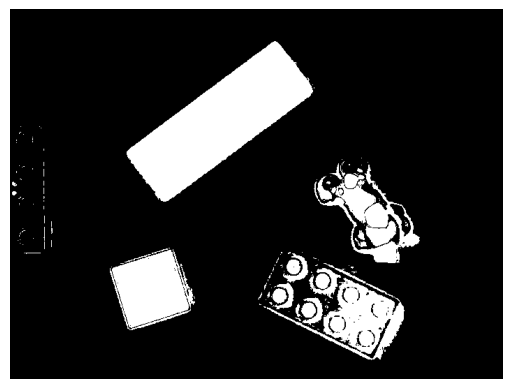

In [518]:
# Binarização

#1ª Maneira:
# def segmentar(img):
#     #fundo = cv2.inRange(img, (150, 90, 0), (255, 200, 110))   # (B, G, R) min e max
#     fundo = cv2.inRange(img, (95, 75, 0), (255, 200, 110))   # mudei por causa das sombras das peças
#     return 255 - fundo                                        # peças = branco, fundo = preto



#2ª Maneira:
#descobre os valores medios de cor(bgr) de fundo de cada imagem
# def cor_fundo(img, faixa=15):
#     # junta as 4 faixas das bordas (cima, baixo, esquerda, direita)
#     bordas = np.concatenate([
#         img[:faixa].reshape(-1, 3),
#         img[-faixa:].reshape(-1, 3),
#         img[:, :faixa].reshape(-1, 3),
#         img[:, -faixa:].reshape(-1, 3),
#     ])
#     # mediana de cada canal (valor que fica no meio): pouco afetada por peças cortadas na borda
#     b, g, r = np.median(bordas, axis=0)
#     return b, g, r

# def segmentar(img):

#     b, g, r = cor_fundo(img)          # cor típica do fundo desta imagem (BGR)

#     #np.clip garante valores entre 0 e 255
#     min = np.clip([b - 45, g - 60, r - 23], 0, 255)
#     max = np.clip([b + 45, g + 60, r + 23], 0, 255)

#     fundo = cv2.inRange(img, min.astype(np.uint8), max.astype(np.uint8))
#     return 255 - fundo               





#3ª Maneira
def cor_fundo(img, faixa=15, folga=10):
    # junta as 4 faixas das bordas (cima, baixo, esquerda, direita)
    bordas = np.concatenate([
        img[:faixa].reshape(-1, 3),
        img[-faixa:].reshape(-1, 3),
        img[:, :faixa].reshape(-1, 3),
        img[:, -faixa:].reshape(-1, 3),
    ])

    # cor típica do fundo (mediana de cada canal)
    b, g, r = np.median(bordas, axis=0)

    # limites do fundo em cada canal: 1% mais baixo e 1% mais alto
    # (ignora os valores extremos, por exemplo uma peça cortada na borda)
    b_min, g_min, r_min = np.percentile(bordas, 1, axis=0)
    b_max, g_max, r_max = np.percentile(bordas, 99, axis=0)

    # variação de cada canal: a maior distância entre a mediana e um dos limites, mais uma folga
    var_b = max(b - b_min, b_max - b) + folga
    var_g = max(g - g_min, g_max - g) + folga
    var_r = max(r - r_min, r_max - r) + folga

    return (b, g, r), (var_b, var_g, var_r)



def segmentar(img):
    (b, g, r), (var_b, var_g, var_r) = cor_fundo(img)

    # igual ao que já tinhas, mas com a variação medida nesta imagem
    inf = np.clip([b - var_b, g - var_g, r - var_r], 0, 255)
    sup = np.clip([b + var_b, g + var_g, r + var_r], 0, 255)

    fundo = cv2.inRange(img, inf.astype(np.uint8), sup.astype(np.uint8))
    return 255 - fundo   # peças = branco, fundo = preto




# estes valores estão em bgr, pq a imagem foi lida assim
print("Canto esquerdo: ", treino[0][10, 10])      # canto
print("Centro: ", treino[0][260, 350])    # centro (zona de fundo)
print("Canto direito", treino[0][500, 20])     # outro canto

binarizacao = [segmentar(img) for img in imagens]

plt.imshow(binarizacao[i],cmap="gray")
plt.axis("off")
plt.show()




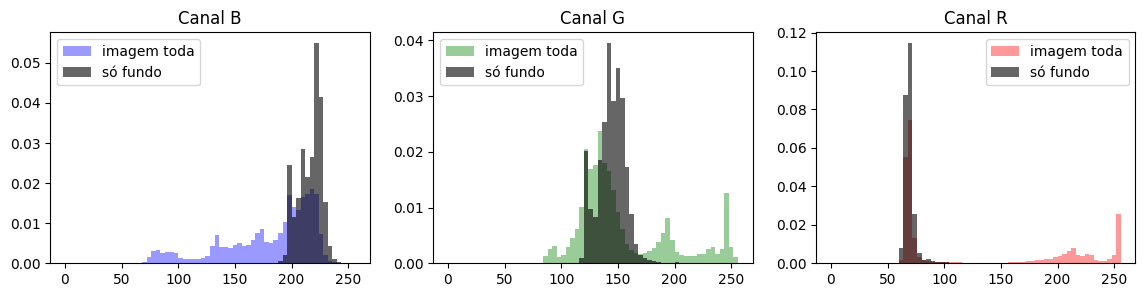

In [519]:
cores = ("b", "g", "r")
img = treino[0]


# amostra só de fundo: as bordas (as mesmas faixas da cor_fundo)
faixa = 15
bordas = np.concatenate([
    img[:faixa].reshape(-1, 3), img[-faixa:].reshape(-1, 3),
    img[:, :faixa].reshape(-1, 3), img[:, -faixa:].reshape(-1, 3),
])

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for k, cor in enumerate(cores):
    ax[k].hist(img[:, :, k].ravel(), bins=64, range=(0, 256), color=cor, alpha=0.4, label="imagem toda", density=True)
    ax[k].hist(bordas[:, k], bins=64, range=(0, 256), color="k", alpha=0.6, label="só fundo", density=True)
    ax[k].set_title(f"Canal {cor.upper()}")
    ax[k].legend()
plt.show()

Os Operadores Morfológicos limpam a imagem binaria antes da extração dos contornos. Faz-se abertura(erosão -> dilatação) para remover as partes brancas e mais pequenas que nao fazem parte das peças. Faz-se o fecho (dilatação -> erosão) para fechar pequenos buracos, como os reflexos nos pinos do Lego. A abertura vem primeiro para remover o ruído antes de fechar, senão o fecho consolidava os pontos de ruído junto às peças e podia voltar a ligar peças proximas. 

A cross ficava com vários pontinhos brancos onde não existiam peças. O rect era bem aproveitado se todas as peças estivessem direitas mas como não estão os cantos comecaçam a desaparecer e a ficar redondos. Então a ellipse foi a melhor opção, uma vez que não deformou as peças, nem acrescentou ruído extra. 

(np.float64(-0.5), np.float64(705.5), np.float64(529.5), np.float64(-0.5))

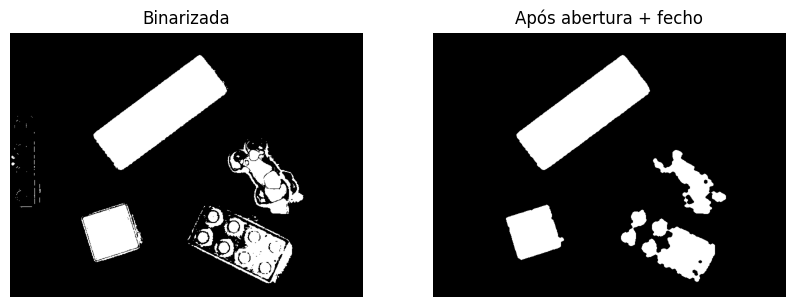

In [520]:
# Operadores Morfológicos

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7)) # elemento estruturante

# O fecho é melhor 

# A função limpar aplica abertura seguida de fecho a uma imagem binária
# Problema: não separam peças muito próximas
def limpar(bin_):
    abertura = cv2.morphologyEx(bin_, cv2.MORPH_OPEN, kernel)    # abertura
    fecho = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, kernel)   # fecho
    return fecho

img_limpo = [limpar(b) for b in binarizacao]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(binarizacao[i], cmap="gray")
ax[0].set_title("Binarizada")
ax[0].axis("off")

ax[1].imshow(img_limpo[i], cmap="gray")
ax[1].set_title("Após abertura + fecho")
ax[1].axis("off")

Erodimos 5 vezes porque testámos a partir da função connectedComponents() e a partir do 5 já resultava o número final de peças. pq...(pesquisar potencial motivo). 

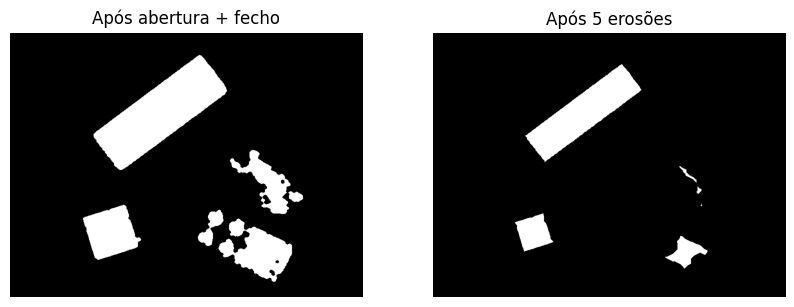

Imagem limpa:  6
Imagem com peças separadas:  6


In [521]:
# Separar peças juntas com Erosão

# A função separar aplica erosão a uma imagem limpa para separar as peças
# o 5 foi escolhido depois de testar com vários valores (célula a seguir)
def separar(limpa, it=5):
    return cv2.erode(limpa, kernel, iterations=it) 

img_sep   = [separar(l) for l in img_limpo]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(img_limpo[i], cmap="gray")
ax[0].set_title("Após abertura + fecho")
ax[0].axis("off")

ax[1].imshow(img_sep[i], cmap="gray")
ax[1].set_title("Após 5 erosões")
ax[1].axis("off")
plt.show()

# ===== Testar a partir da etiquetação =====

resultado_limpo = [cv2.connectedComponents(tl) for tl in img_limpo] # lista de tuplos: (número de objetos, etiquetas)
resultado_sep= [cv2.connectedComponents(ts) for ts in img_sep] 
# [x][0] -> n objetos
# [x][1] -> etiquetas

print("Imagem limpa: ", resultado_limpo[i][0] - 1) # 0 é o fundo, daí subtraí-se 1
print("Imagem com peças separadas: ", resultado_sep[i][0] - 1) 

A imagem original tem 4 peças mas duas juntas, e usando a imagem limpa apenas se detetam 3 peças
Na imagem com peças separadas já dá o resultado correto

O connectedComponents devolve as regiões identificadas, mas não fornece diretamente os contornos necessários para o método de classificação que implementaste. Então para a etiquetação utilizamos o findContours, que permite obter os contornos de cada objeto, que são necessários para calcular as medidas utilizadas na classificação.

Número de objetos encontrados:  6


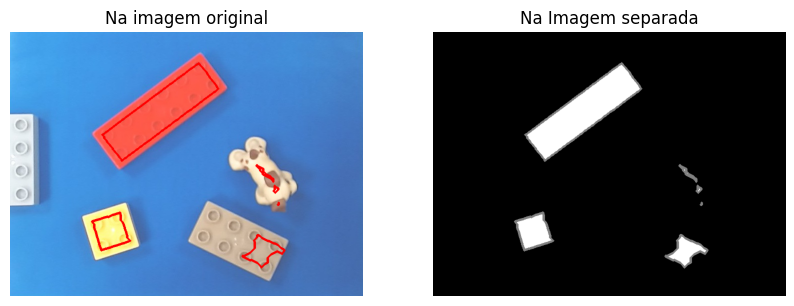

In [522]:
# Etiquetação

# findContours -> devolve uma lista de pontos da fronteira, e cada contorno corresponde a um objeto.
# drawContours desenha esses contornos, ou preenche-os se thickness=-1, o que dá uma máscara por peça.
# Os contornos servem depois para o próximo passo

contornos = [cv2.findContours(ts, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0] for ts in img_sep]
# RETR_EXTERNAL apanha só os contornos exteriores
# CHAIN_APPROX_SIMPLE guarda só os pontos finais de cada linha (poupa memória)
# [0] -> só para obter os contornos pq a função devolve um tuplo mas só precisamos do primeiro elemento



contorno = contornos[i]
print("Número de objetos encontrados: ", len(contorno)) 

org = imagens[i].copy()
cv2.drawContours(org, contorno, -1, (0, 0, 255), 3)

sep = img_sep[i].copy()
cv2.drawContours(sep, contorno, -1, 128, 3) # contornos a cinzento

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(org[:, :, ::-1])
ax[0].set_title("Na imagem original")
ax[0].axis("off")

ax[1].imshow(sep, cmap="gray")
ax[1].set_title("Na Imagem separada")
ax[1].axis("off")
plt.show()

Na imagem original os contornos estão mais pequenos porque as erosões diminuiram os tamanhos das peças.

minAreaRect: Melhor escolha. As razões teóricas são 1, 2, 3 e 4, e não dependem da rotação da peça.
contourArea: Boa, como confirmação. Proporcional ao nº de pinos (4, 8, 12, 16), e como a câmara é paralela à mesa e está fixa, a escala é constante
contourArea + minAreaRect: Boa para filtrar ruído. Peças retangulares dão valores próximos de 1, e as outras peças de Lego presentes na imagem ficam abaixo.

In [523]:
margem = 5 * 3 * 2 # número de erosões * raio do elemento estruturante * lados - isto tudo é o númeor de px perdidos nas erosões, numa dimensao (ou w, ou h)
# 5 × 3 = 15 px são o que se perde num lado
# O elemento é uma elipse de 7x7 píxeis, ou seja, tem um centro e 3 píxeis para cada lado (3 + 1 + 3 = 7).
# A largura tem dois lados (esquerdo e direito), por isso perde 2 × 15 = 30 px
# O comprimento também tem dois lados (cima e baixo), por isso também perde 30 px
# Por isso a margem é somada à largura e ao comprimento (*AQUI)


# função que recebe um contorno e devolve as suas medidas num dicionário
def medir(contorno):
    
    (cx, cy), (w, h), _ = cv2.minAreaRect(contorno)
    # minAreaRect calcula o menor retângulo, possivelmente rodado, que contém o contorno
    # (cx, cy): o centro do retângulo
    # (w, h): a largura e a altura desse retângulo

    area = cv2.contourArea(contorno) 
    # Área da região dentro do contorno, em píxeis. É a área da peça real (depois da erosão), e não a do retângulo.

    ret = area / (w * h) # retangularidade (sem compensação, é só uma razão de áreas)
    # Retangularidade: área da peça real a dividir pela área do retângulo
    # Se a peça for um retângulo perfeito, os dois valores coincidem e o resultado é 1
    # Se for outra forma, a peça preenche só parte do retângulo e o valor desce (o semicírculo deu cerca de 0,79)
    # Está antes da compensação de propósito: a area do contorno é a erosionada, por isso w * h também tem de ser 
    # Se somasse a margem primeiro, estaria a comparar uma área pequena com um retângulo já “reposto”, 
    # e a razão ficaria errada. Na verdade, a erosão tira o mesmo número de px (30) a cada dimensão, e não uma percentagem. Por isso a razão muda e deixa de dar 1, 2, 3, 4, 
    #o que estragaria as nossas referências para classificar. 

    w += margem # (*AQUI)
    h += margem # (*AQUI)

    maior, menor = max(w, h), min(w, h)
    # minAreaRect pode devolver w como o lado curto ou o comprido, conforme a rotação da peça
    # Com max e min, maior é sempre o lado comprido e menor o lado curto 
    # Assim a razão maior / menor é sempre ≥ 1 e não depende da orientação.

    return {"centro": (cx, cy), "maior": maior, "menor": menor,
            "razao": maior / menor, "area": area, "retangularidade": ret}


for c in contorno:
    m = medir(c)
    print(f"img {i} | razão {m['razao']:.2f} | área {m['area']:.0f} | ret {m['retangularidade']:.2f}")
    # NECESSÁRIO PERCORRER TODAS DE TREINO PARA ANALISAR MELHOR OS VALORES E TIRAR CONCLUSÕES

img 3 | razão 1.14 | área 2241 | ret 0.60
img 3 | razão 1.00 | área 3465 | ret 0.92
img 3 | razão 1.06 | área 2 | ret 0.25
img 3 | razão 1.01 | área 64 | ret 0.57
img 3 | razão 1.99 | área 159 | ret 0.40
img 3 | razão 2.83 | área 15672 | ret 0.97


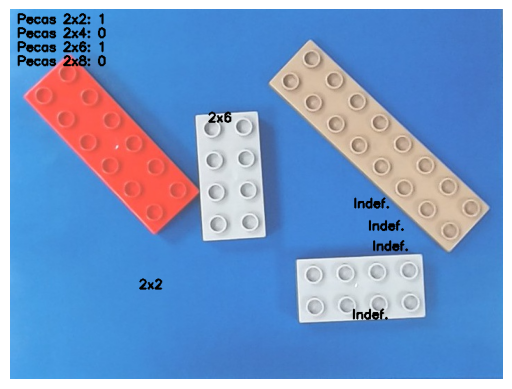

In [524]:
# Classificação

def classificar(m):
    # rejeitar o que não é retangular (semicírculo, outras peças, ruído)
    if m["retangularidade"] < 0.85:
        return None
    r = m["razao"]
    # classificar pela razão, com zonas de rejeição entre as classes
    if 0.85 <= r <= 1.25:
        return "2x2"
    elif 1.75 <= r <= 2.25:
        return "2x4"
    elif 2.6 <= r <= 3.3:
        return "2x6"
    elif 3.5 <= r <= 4.3:
        return "2x8"
    return None   # razão fora das classes (ex.: peça vermelha curva, 1.54)

# Escreve na imagem as peças identificadas
def contar(conts, img_cor):
    contagem = {"2x2": 0, "2x4": 0, "2x6": 0, "2x8": 0}
    saida = img_cor.copy()

    for c in conts:
        m = medir(c) # métricas
        tipo = classificar(m) # classificação

        cx, cy = m["centro"]

        if tipo is None:
            cv2.putText(saida, "Indef.", (int(cx) - 17, int(cy)), # imagem, texto, posição
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) # fonte, tamanho, cor, espessura
            continue

        contagem[tipo] += 1
        
        cv2.putText(saida, tipo, (int(cx) - 17, int(cy)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2) 

    # resumo no canto superior esquerdo
    for k, tipo in enumerate(["2x2", "2x4", "2x6", "2x8"]):
        cv2.putText(saida, f"Pecas {tipo}: {contagem[tipo]}", (10, 20 + 20 * k),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return saida

saida = contar(contornos[i], treino[i])
plt.imshow(saida[:, :, ::-1])
plt.axis("off")
plt.show()

a peça vermelha é 2x4 no entanto como está vista de um angulo onde se vê a altura, ao calcular a área ficaria fora do intervalo esperado ou de qualquer outro intervalo sendo o mais correto porque se não deteta que é 2x4 mais vale ser rejeitada do que mal classificada.